# Projeto gmxflow

Este notebook é um ponto de entrada para trabalhar com este projeto. A configuração científica continua em `project.toml`; revise entradas, campo de força e parâmetros antes de executar.

A API Python usada aqui ainda é experimental. A execução pode consumir bastante tempo e recursos computacionais, dependendo da configuração. Se `simulation.profile = "smoke"`, os resultados servem apenas para verificar a integração do software e não têm interpretação científica.

## 1. Abrir o projeto

Coloque os arquivos de entrada na pasta `inputs/` e ajuste os caminhos correspondentes em `project.toml`.

In [2]:
from pathlib import Path
from gmxflow.api import GmxFlowProject

project_config = Path('project.toml')
if not project_config.is_file():
    project_config = Path('examples/smoke_peptide_complex/project.toml')

project = GmxFlowProject.open(project_config)
print('Projeto aberto.')

Projeto aberto.


## 2. Verificar se está tudo pronto

Esta verificação confere os arquivos, o GROMACS e o campo de força. Ela não inicia a simulação.

In [3]:
project.validate()
print('Pré-requisitos verificados.')

Pré-requisitos verificados.


## 3. Executar a simulação

> Antes de executar, confira os parâmetros em `project.toml` e os arquivos em `inputs/`. Esta célula monta os Steps do projeto e executa o workflow completo.

In [4]:
workflow = project.workflow()
execution_report = project.run_workflow(workflow)
project.show_execution(execution_report)

### Resumo da execução

,Etapa,Status,Duração (s),Log
0,prepare,concluída,1.194,/home/michel/Devel/gmxflow/examples/smoke_peptide_complex/work/logs/01_prepare.log
1,topology,concluída,0.114,/home/michel/Devel/gmxflow/examples/smoke_peptide_complex/work/logs/02_topology.log
2,box,concluída,0.018,/home/michel/Devel/gmxflow/examples/smoke_peptide_complex/work/logs/03_box.log
3,solvate,concluída,1.005,/home/michel/Devel/gmxflow/examples/smoke_peptide_complex/work/logs/04_solvate.log
4,ions-grompp,concluída,0.072,/home/michel/Devel/gmxflow/examples/smoke_peptide_complex/work/logs/05_ions-grompp.log
5,ions,concluída,1.162,/home/michel/Devel/gmxflow/examples/smoke_peptide_complex/work/logs/06_ions.log
6,em-grompp,concluída,0.040,/home/michel/Devel/gmxflow/examples/smoke_peptide_complex/work/logs/07_em-grompp.log
7,em,concluída,1.042,/home/michel/Devel/gmxflow/examples/smoke_peptide_complex/work/logs/08_em.log
8,nvt-grompp,concluída,0.074,/home/michel/Devel/gmxflow/examples/smoke_peptide_complex/work/logs/09_nvt-grompp.log
9,nvt,concluída,0.247,/home/michel/Devel/gmxflow/examples/smoke_peptide_complex/work/logs/10_nvt.log


## 4. Abrir o relatório

O relatório será exibido aqui. A versão HTML para compartilhar também fica disponível em `outputs/report.html`.

# smoke_peptide_complex

Exemplo mínimo para testar executor e logs do gmxflow

## Resumo

,Item,Valor
0,Perfil,smoke
1,Passos de produção,10
2,RMSD backbone médio,0.004 +/- 0.003 nm
3,RMSD ligante médio,0.005 +/- 0.002 nm
4,Contatos médios,71.545 +/- 1.076 átomos
5,H-bonds médios,0.455 +/- 0.498 ligações


### Avisos
- Perfil smoke: resultados servem apenas para validar a pipeline, não para interpretação científica.

## Execução

... (2 outputs left out)

## Análises

,Métrica,Média,Desvio padrão,Mínimo,Máximo,Pontos,Fração > 0,Unidade
0,RMSD do backbone,0.004449,0.002641,0.000454,0.008818,11,NaN,nm
1,RMSD do ligante,0.004542,0.002152,0.000390,0.007002,11,NaN,nm
2,RMSF por resíduo,0.002960,0.001076,0.002100,0.005000,5,NaN,nm
3,Raio de giro,0.386456,0.000847,0.385172,0.387884,11,NaN,nm
4,Distância mínima receptor-ligante,0.218957,0.004050,0.210069,0.223350,11,NaN,nm
5,Contatos receptor-ligante,71.545455,1.075651,70.000000,73.000000,11,1.000000,átomos
6,Pontes de hidrogênio receptor-ligante,0.454545,0.497930,0.000000,1.000000,11,0.454545,ligações
7,Energia potencial após minimização,-21216.859928,3462.639052,-23546.121094,1929.808838,102,NaN,kJ/mol
8,Temperatura durante NVT,259.461518,41.653106,217.808411,301.114624,2,NaN,K
9,Pressão durante NPT,1328.410247,502.123565,826.286682,1830.533813,2,NaN,bar


## Gráficos

### Rmsd Bb

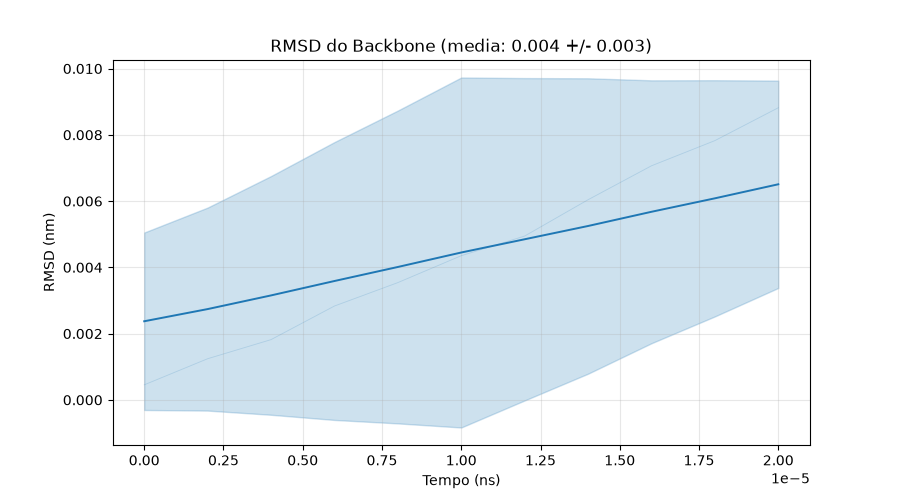

### Rmsd Lig

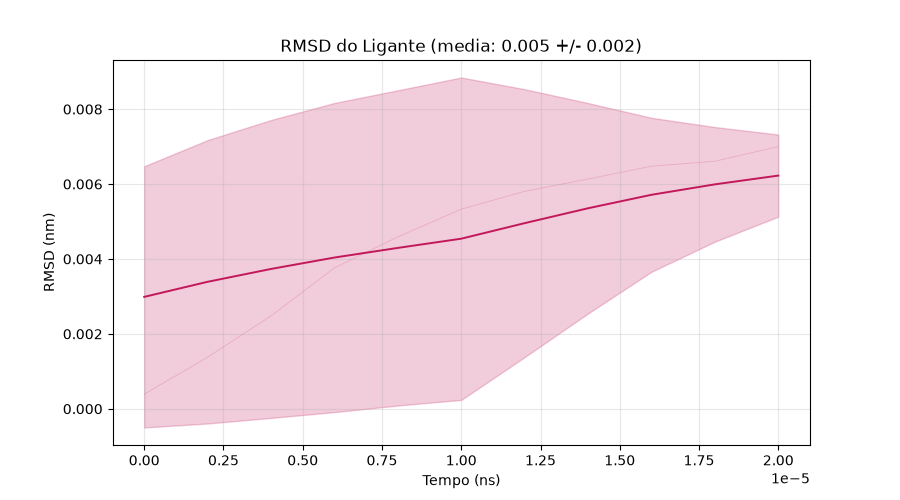

### Rmsf

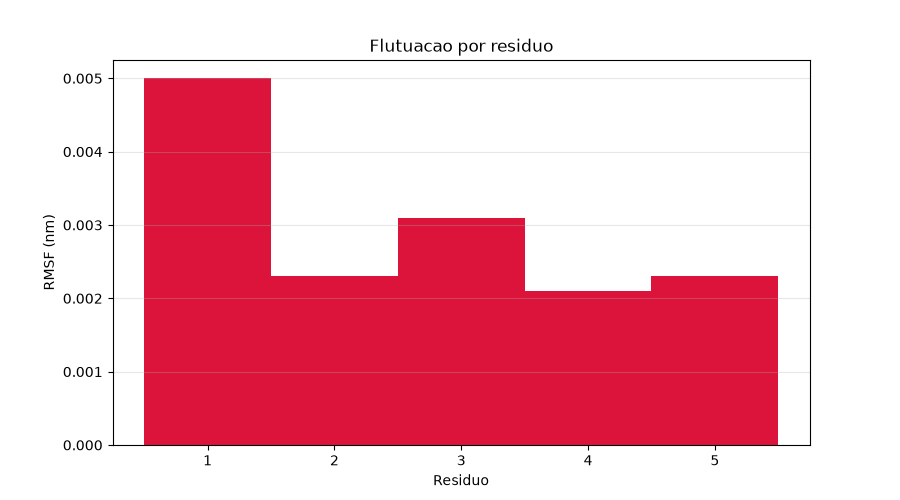

### Rg

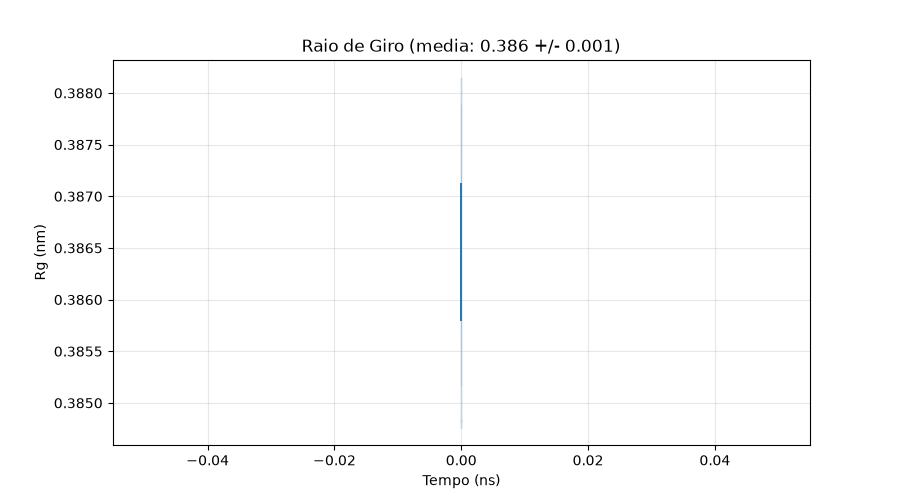

### Ncont

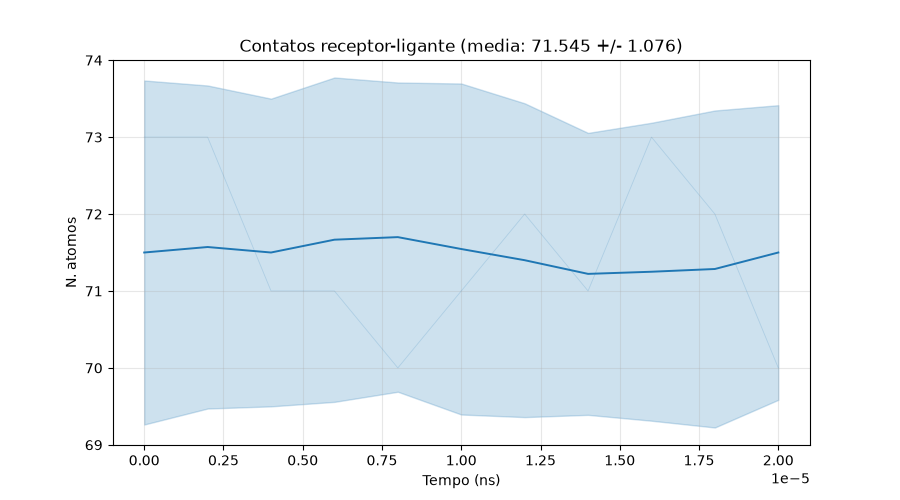

### Hbond

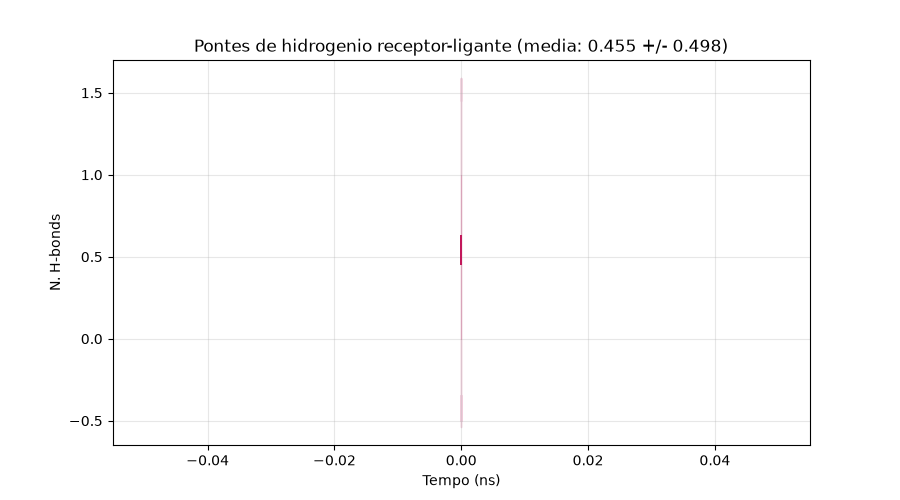

### Em Potential

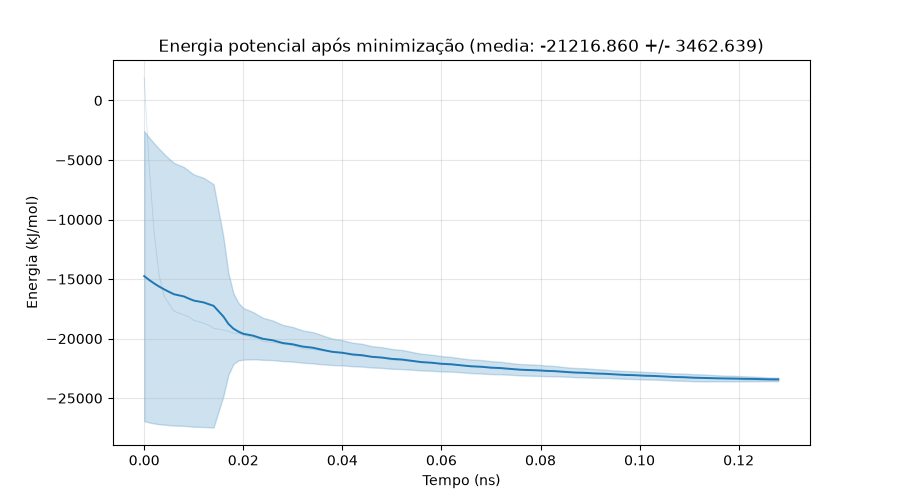

### Nvt Temperature

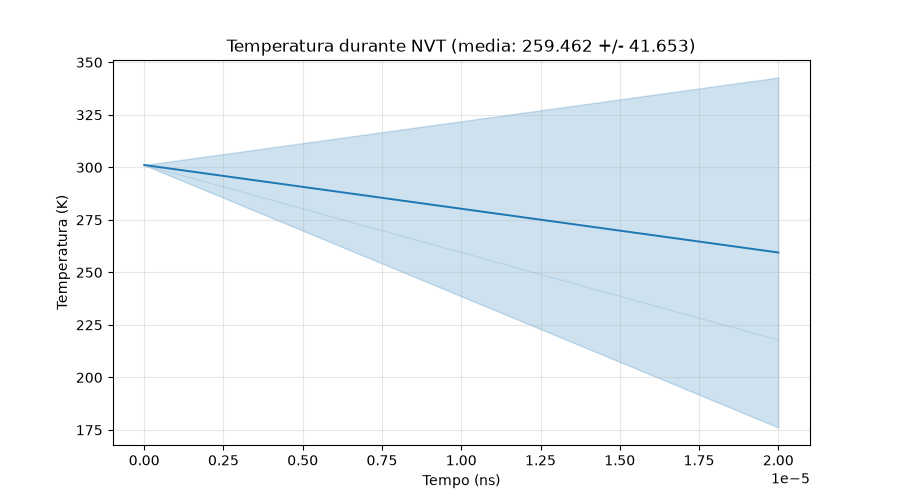

### Npt Pressure

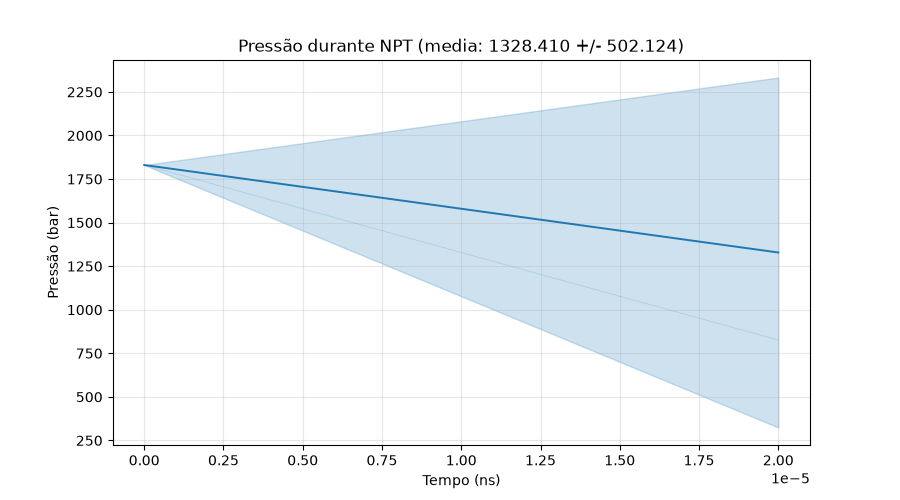

### Npt Density

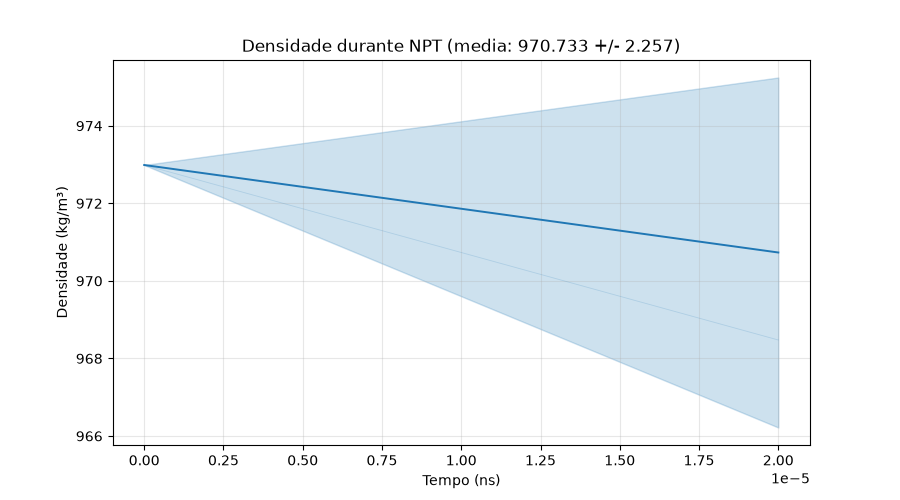

Relatório distribuível: `outputs/report.html`

In [5]:
project.show_report()